# Упражнение: классификатор Softmax

В этом упражнении вы:

- реализуете полностью векторизованную **функцию потерь** для классификатора Softmax;
- реализуете полностью векторизованное выражение для её **аналитического градиента**;
- **проверите свою реализацию** с помощью численного градиента;
- с помощью валидационной выборки **подберёте скорость обучения (learning rate) и коэффициент регуляризации**;
- **оптимизируете** функцию потерь с помощью **SGD**;
- **визуализируете** итоговые обученные веса.


In [11]:
# Настройка окружения (запустите эту ячейку первой).
# Откройте ноутбук из папки python/ задания, например: uv run jupyter lab
# При первом запуске скачается CIFAR-10 (~170 МБ): с сервера курса, а если он
# недоступен, с официального сайта. Источник можно задать явно переменной
# окружения DLCV_DATASET_SOURCE=racoon или official перед запуском Jupyter.
import os
import sys

if not os.path.isdir('dlcv'):
    raise FileNotFoundError(
        'В текущей папке нет пакета dlcv. Откройте ноутбук из папки python/ задания.')
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

from dlcv.data_utils import ensure_cifar10
ensure_cifar10()
print('Рабочая папка:', os.getcwd())

Рабочая папка: c:\Users\Artemiy\Desktop\MAGA\DL\dl-assignment1-template\python


In [12]:
# Подготовительный код для этого ноутбука.
import random
import numpy as np
from dlcv.data_utils import load_CIFAR10
import matplotlib.pyplot as plt

# Немного магии, чтобы графики matplotlib отображались прямо в ноутбуке,
# а не в отдельном окне.
%matplotlib inline
plt.rcParams['figure.figsize'] = (10.0, 8.0) # размер графиков по умолчанию
plt.rcParams['image.interpolation'] = 'nearest'
plt.rcParams['image.cmap'] = 'gray'

# Ещё немного магии, чтобы ноутбук автоматически перезагружал внешние модули Python;
# см. http://stackoverflow.com/questions/1907993/autoreload-of-modules-in-ipython
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Загрузка и предобработка данных CIFAR-10

In [13]:
# Загружаем исходные данные CIFAR-10.
cifar10_dir = 'dlcv/datasets/cifar-10-batches-py'

# Удаляем переменные, чтобы не загружать данные несколько раз (иначе может не хватить памяти)
try:
   del X_train, y_train
   del X_test, y_test
   print('Ранее загруженные данные удалены.')
except:
   pass

X_train, y_train, X_test, y_test = load_CIFAR10(cifar10_dir)

# Для быстрой проверки выведем формы массивов обучающих и тестовых данных.
print('Форма обучающих данных: ', X_train.shape)
print('Форма обучающих меток: ', y_train.shape)
print('Форма тестовых данных: ', X_test.shape)
print('Форма тестовых меток: ', y_test.shape)

Ранее загруженные данные удалены.
Форма обучающих данных:  (50000, 32, 32, 3)
Форма обучающих меток:  (50000,)
Форма тестовых данных:  (10000, 32, 32, 3)
Форма тестовых меток:  (10000,)


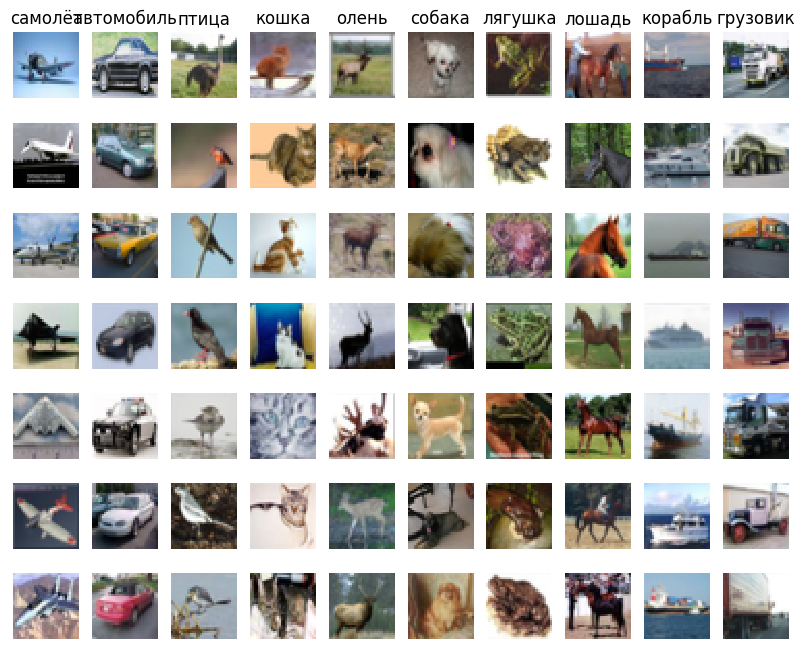

In [14]:
# Визуализируем несколько примеров из набора данных.
# Для каждого класса покажем несколько обучающих изображений.
classes = ['самолёт', 'автомобиль', 'птица', 'кошка', 'олень', 'собака', 'лягушка', 'лошадь', 'корабль', 'грузовик']
num_classes = len(classes)
samples_per_class = 7
for y, cls in enumerate(classes):
    idxs = np.flatnonzero(y_train == y)
    idxs = np.random.choice(idxs, samples_per_class, replace=False)
    for i, idx in enumerate(idxs):
        plt_idx = i * num_classes + y + 1
        plt.subplot(samples_per_class, num_classes, plt_idx)
        plt.imshow(X_train[idx].astype('uint8'))
        plt.axis('off')
        if i == 0:
            plt.title(cls)
plt.show()

In [15]:
# Разбиваем данные на обучающую, валидационную и тестовую выборки. Кроме того,
# создадим небольшую отладочную (dev) выборку как подмножество обучающих данных:
# на ней удобно отлаживать код, потому что он будет выполняться быстрее.
num_training = 49000
num_validation = 1000
num_test = 1000
num_dev = 500

# Валидационная выборка — это num_validation объектов из исходной
# обучающей выборки.
mask = range(num_training, num_training + num_validation)
X_val = X_train[mask]
y_val = y_train[mask]

# Обучающая выборка — это первые num_training объектов исходной
# обучающей выборки.
mask = range(num_training)
X_train = X_train[mask]
y_train = y_train[mask]

# Также создадим отладочную (dev) выборку — небольшое подмножество
# обучающей выборки.
mask = np.random.choice(num_training, num_dev, replace=False)
X_dev = X_train[mask]
y_dev = y_train[mask]

# В качестве тестовой выборки берём первые num_test объектов исходной
# тестовой выборки.
mask = range(num_test)
X_test = X_test[mask]
y_test = y_test[mask]

print('Форма обучающих данных: ', X_train.shape)
print('Форма обучающих меток: ', y_train.shape)
print('Форма валидационных данных: ', X_val.shape)
print('Форма валидационных меток: ', y_val.shape)
print('Форма тестовых данных: ', X_test.shape)
print('Форма тестовых меток: ', y_test.shape)

Форма обучающих данных:  (49000, 32, 32, 3)
Форма обучающих меток:  (49000,)
Форма валидационных данных:  (1000, 32, 32, 3)
Форма валидационных меток:  (1000,)
Форма тестовых данных:  (1000, 32, 32, 3)
Форма тестовых меток:  (1000,)


In [16]:
# Предобработка: вытягиваем каждое изображение в строку
X_train = np.reshape(X_train, (X_train.shape[0], -1))
X_val = np.reshape(X_val, (X_val.shape[0], -1))
X_test = np.reshape(X_test, (X_test.shape[0], -1))
X_dev = np.reshape(X_dev, (X_dev.shape[0], -1))

# Для быстрой проверки выведем формы массивов данных
print('Форма обучающих данных: ', X_train.shape)
print('Форма валидационных данных: ', X_val.shape)
print('Форма тестовых данных: ', X_test.shape)
print('Форма отладочных (dev) данных: ', X_dev.shape)

Форма обучающих данных:  (49000, 3072)
Форма валидационных данных:  (1000, 3072)
Форма тестовых данных:  (1000, 3072)
Форма отладочных (dev) данных:  (500, 3072)


[130.64189796 135.98173469 132.47391837 130.05569388 135.34804082
 131.75402041 130.96055102 136.14328571 132.47636735 131.48467347]


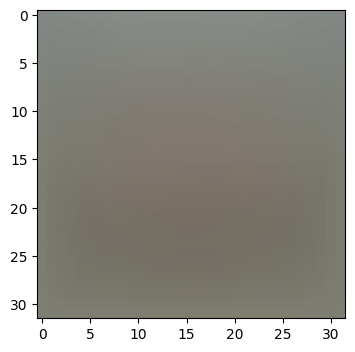

(49000, 3073) (1000, 3073) (1000, 3073) (500, 3073)


In [17]:
# Предобработка: вычитаем среднее изображение
# шаг 1: вычисляем среднее изображение по обучающим данным
mean_image = np.mean(X_train, axis=0)
print(mean_image[:10]) # выводим несколько первых элементов
plt.figure(figsize=(4,4))
plt.imshow(mean_image.reshape((32,32,3)).astype('uint8')) # визуализируем среднее изображение
plt.show()

# шаг 2: вычитаем среднее изображение из данных всех выборок
X_train -= mean_image
X_val -= mean_image
X_test -= mean_image
X_dev -= mean_image

# шаг 3: дописываем к данным столбец из единиц для смещения («трюк со смещением»,
# bias trick), чтобы классификатору нужно было оптимизировать только одну
# матрицу весов W.
X_train = np.hstack([X_train, np.ones((X_train.shape[0], 1))])
X_val = np.hstack([X_val, np.ones((X_val.shape[0], 1))])
X_test = np.hstack([X_test, np.ones((X_test.shape[0], 1))])
X_dev = np.hstack([X_dev, np.ones((X_dev.shape[0], 1))])

print(X_train.shape, X_val.shape, X_test.shape, X_dev.shape)

## Классификатор Softmax

Весь код для этого раздела пишется в файле `dlcv/classifiers/softmax.py`.

В этом файле уже есть функция `softmax_loss_naive`, в которой вычисление значения функции потерь softmax с помощью циклов `for` написано за вас; градиент вы допишете в ней ниже.

In [18]:
# Проверим наивную реализацию функции потерь (значение потерь в ней уже вычисляется):
from dlcv.classifiers.softmax import softmax_loss_naive
import time

# генерируем случайную матрицу весов классификатора Softmax из маленьких чисел
W = np.random.randn(3073, 10) * 0.0001

loss, grad = softmax_loss_naive(W, X_dev, y_dev, 0.000005)

# Грубая проверка на здравый смысл: значение потерь должно быть близко к -log(0.1).
print('потери: %f' % loss)
print('ожидаемое значение, -log(0.1): %f' % (-np.log(0.1)))

потери: 2.381875
ожидаемое значение, -log(0.1): 2.302585


**Вопрос 1**

Почему следует ожидать, что значение потерь окажется близким к -log(0.1)? Объясните кратко.

**Ваш ответ:** начальные веса близки к нулю, поэтому оценки всех десяти классов почти одинаковы. Softmax назначает каждому классу вероятность около 0.1, а потеря для правильного класса равна отрицательному логарифму этой вероятности


Сейчас градиент `grad`, который возвращает функция выше, целиком состоит из нулей. Выведите формулу градиента функции потерь softmax и реализуйте её прямо внутри функции `softmax_loss_naive`. Удобнее всего встроить новый код в уже написанный код этой функции.

Чтобы убедиться, что градиент реализован правильно, можно численно оценить градиент функции потерь и сравнить эту оценку с градиентом, который вычислили вы. Код, который это делает, уже готов:

In [19]:
# Когда вы реализуете градиент, пересчитайте его с помощью кода ниже
# и выполните проверку градиента (gradient check) готовой функцией

# Вычисляем значение потерь и градиент в точке W.
loss, grad = softmax_loss_naive(W, X_dev, y_dev, 0.0)

# Численно вычисляем градиент по нескольким случайно выбранным координатам и
# сравниваем его с вычисленным вами аналитическим градиентом. Числа должны
# почти точно совпадать по всем координатам.
from dlcv.gradient_check import grad_check_sparse
f = lambda w: softmax_loss_naive(w, X_dev, y_dev, 0.0)[0]
grad_numerical = grad_check_sparse(f, W, grad)

# ещё раз проверяем градиент, теперь с включённой регуляризацией.
# вы ведь не забыли про градиент регуляризации?
loss, grad = softmax_loss_naive(W, X_dev, y_dev, 5e1)
f = lambda w: softmax_loss_naive(w, X_dev, y_dev, 5e1)[0]
grad_numerical = grad_check_sparse(f, W, grad)

численный: -4.261597 аналитический: -4.261597, относительная ошибка: 1.217017e-08
численный: 3.286335 аналитический: 3.286335, относительная ошибка: 3.662227e-10
численный: -2.188777 аналитический: -2.188777, относительная ошибка: 5.359124e-09
численный: 2.912000 аналитический: 2.912000, относительная ошибка: 1.718025e-08
численный: 0.091167 аналитический: 0.091166, относительная ошибка: 5.668698e-07
численный: 1.041708 аналитический: 1.041708, относительная ошибка: 6.314009e-08
численный: 2.688407 аналитический: 2.688407, относительная ошибка: 3.677063e-09
численный: -2.461122 аналитический: -2.461122, относительная ошибка: 6.232911e-10
численный: -3.460207 аналитический: -3.460207, относительная ошибка: 5.595242e-10
численный: -0.679135 аналитический: -0.679135, относительная ошибка: 1.724731e-08
численный: -0.120577 аналитический: -0.120577, относительная ошибка: 2.430534e-07
численный: 0.132781 аналитический: 0.132781, относительная ошибка: 3.215225e-07
численный: 2.917155 аналитич

**Вопрос 2**

Для функции потерь softmax проверка градиента работает надёжно, но для функции потерь SVM иногда бывает, что по какой-нибудь координате численный и аналитический градиенты не совпадают точно. Чем может быть вызвано такое расхождение? Стоит ли из-за него беспокоиться? Приведите простой одномерный пример, в котором проверка градиента для функции потерь SVM может не пройти. Как изменение зазора (margin) повлияет на то, как часто это происходит?

Отметим, что функция потерь SVM (многоклассовая hinge loss) для объекта $(x_i, y_i)$ определяется так: $$L_i = \sum_{j\ne y_i}\max(0, s_j - s_{y_i} + \Delta)$$ где $j$ пробегает все классы, кроме правильного класса $y_i$, а $s_j$ — оценка (score) классификатора для $j$-го класса; $\Delta$ — скалярный зазор (margin). Иными словами, штраф за неправильный класс $j$ равен нулю, если оценка правильного класса больше его оценки хотя бы на $\Delta$, и положителен в противном случае.

*Подсказка: функция потерь SVM, строго говоря, не является дифференцируемой.*

**Ваш ответ:** 

SVM loss содержит функцию max(0, x), которая не дифференцируема в точке x=0. Если при численной проверке значения по разные стороны небольшого шага попадают на разные ветви функции, численный и аналитический градиенты могут различаться. Например, для f(x)=max(0,x) в точке x=0 аналитическая реализация может вернуть 0, а центральная численная оценка даст 0.5. Редкие расхождения в точках излома не означают ошибку. Изменение margin перемещает границу излома и поэтому меняет число примеров рядом с ней; чем больше таких примеров, тем чаще возможны расхождения.


In [21]:
# Теперь реализуйте функцию softmax_loss_vectorized; пока вычисляйте в ней
# только значение потерь, градиент реализуем чуть позже.
tic = time.time()
loss_naive, grad_naive = softmax_loss_naive(W, X_dev, y_dev, 0.000005)
toc = time.time()
print('Наивная реализация: потери %e, время вычисления %f с' % (loss_naive, toc - tic))

from dlcv.classifiers.softmax import softmax_loss_vectorized
tic = time.time()
loss_vectorized, _ = softmax_loss_vectorized(W, X_dev, y_dev, 0.000005)
toc = time.time()
print('Векторизованная реализация: потери %e, время вычисления %f с' % (loss_vectorized, toc - tic))

# Значения потерь должны совпадать, но векторизованная реализация должна работать намного быстрее.
print('разница: %f' % (loss_naive - loss_vectorized))

Наивная реализация: потери 2.381875e+00, время вычисления 0.034887 с
Векторизованная реализация: потери 2.381875e+00, время вычисления 0.002013 с
разница: 0.000000


In [23]:
# Завершите реализацию softmax_loss_vectorized: вычислите градиент функции
# потерь векторизованным способом.

# Результаты наивной и векторизованной реализаций должны совпадать, но
# векторизованная версия по-прежнему должна работать намного быстрее.
tic = time.time()
_, grad_naive = softmax_loss_naive(W, X_dev, y_dev, 0.000005)
toc = time.time()
print('Наивная реализация, потери и градиент: время вычисления %f с' % (toc - tic))

tic = time.time()
_, grad_vectorized = softmax_loss_vectorized(W, X_dev, y_dev, 0.000005)
toc = time.time()
print('Векторизованная реализация, потери и градиент: время вычисления %f с' % (toc - tic))

# Значение потерь — это одно число, поэтому результаты двух реализаций легко
# сравнить. Градиент же — матрица, поэтому для сравнения используем норму
# Фробениуса.
difference = np.linalg.norm(grad_naive - grad_vectorized, ord='fro')
print('разница: %f' % difference)

Наивная реализация, потери и градиент: время вычисления 0.035752 с
Векторизованная реализация, потери и градиент: время вычисления 0.002079 с
разница: 0.000000


### Стохастический градиентный спуск

Теперь у вас есть эффективные векторизованные выражения для функции потерь и её градиента, причём градиент совпадает с численным. Значит, всё готово к тому, чтобы минимизировать функцию потерь с помощью SGD. Код для этой части пишется в файле `dlcv/classifiers/linear_classifier.py`.

In [26]:
# Реализуйте SGD в методе LinearClassifier.train() в файле linear_classifier.py,
# а затем запустите обучение с помощью кода ниже.
from dlcv.classifiers import Softmax
softmax = Softmax()
tic = time.time()
loss_hist = softmax.train(X_train, y_train, learning_rate=1e-7, reg=2.5e4,
                      num_iters=1500, verbose=True)
toc = time.time()
print('Обучение заняло %f с' % (toc - tic))

итерация 0 / 1500: потери 779.151144
итерация 100 / 1500: потери 285.453168
итерация 200 / 1500: потери 105.885423
итерация 300 / 1500: потери 40.038302
итерация 400 / 1500: потери 16.023907
итерация 500 / 1500: потери 7.110701
итерация 600 / 1500: потери 3.908358
итерация 700 / 1500: потери 2.720169
итерация 800 / 1500: потери 2.301374
итерация 900 / 1500: потери 2.216448
итерация 1000 / 1500: потери 2.110144
итерация 1100 / 1500: потери 2.105438
итерация 1200 / 1500: потери 2.108421
итерация 1300 / 1500: потери 2.055818
итерация 1400 / 1500: потери 2.106348
Обучение заняло 2.855569 с


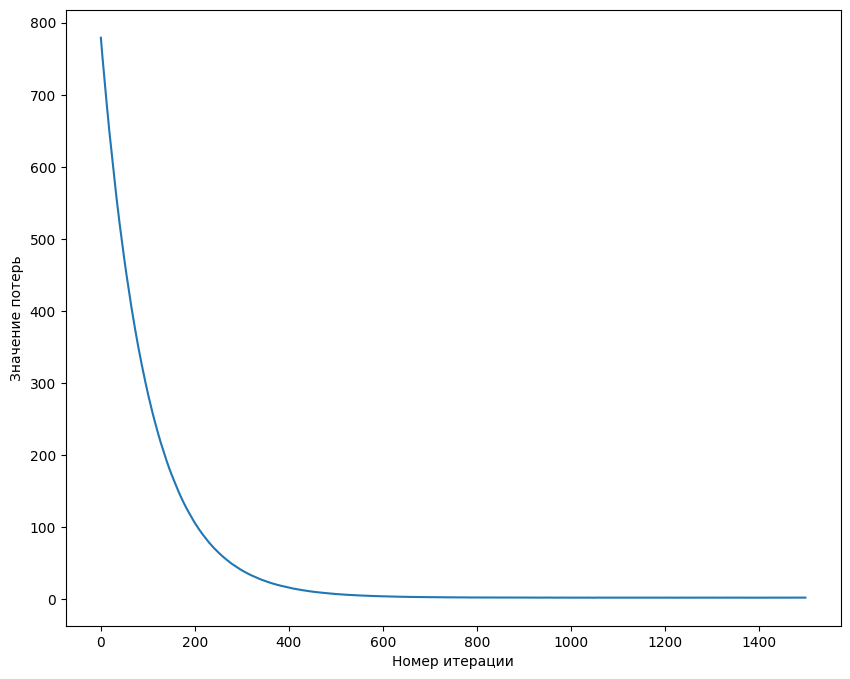

In [27]:
# Полезный приём при отладке — построить график значения потерь
# в зависимости от номера итерации:
plt.plot(loss_hist)
plt.xlabel('Номер итерации')
plt.ylabel('Значение потерь')
plt.show()

In [28]:
# Реализуйте функцию LinearClassifier.predict и оцените качество классификатора
# на обучающей и валидационной выборках.
# Точность (accuracy, доля правильных ответов) на валидационной выборке должна
# получиться около 0.34 (> 0.33).
y_train_pred = softmax.predict(X_train)
print('точность на обучающей выборке: %f' % (np.mean(y_train == y_train_pred), ))
y_val_pred = softmax.predict(X_val)
print('точность на валидационной выборке: %f' % (np.mean(y_val == y_val_pred), ))

точность на обучающей выборке: 0.328286
точность на валидационной выборке: 0.339000


In [29]:
# Сохраняем обученную модель (файл появится в папке `dlcv/saved/`).
softmax.save("softmax.npy")

softmax.npy сохранён.


In [34]:
# Используйте валидационную выборку для подбора гиперпараметров (коэффициента
# регуляризации и скорости обучения). Поэкспериментируйте с разными диапазонами
# скоростей обучения и коэффициентов регуляризации; при аккуратном подборе
# точность классификации на валидационной выборке должна получиться не ниже
# 0.36 (при удачном подборе — около 0.40).

# Примечание: во время подбора гиперпараметров могут появляться предупреждения
# RuntimeWarning (например, о переполнении — overflow). Их могут вызывать
# экстремальные значения гиперпараметров, и это не ошибка в коде.

# results — словарь, который сопоставляет кортежам вида
# (learning_rate, regularization_strength) кортежи вида
# (training_accuracy, validation_accuracy). Точность — это просто доля
# правильно классифицированных объектов.
results = {}
best_val = -1   # Наибольшая точность на валидационной выборке на данный момент.
best_softmax = None # Объект Softmax, показавший наибольшую точность на валидационной выборке.

################################################################################
# TODO:                                                                        #
# Напишите код, который выбирает лучшие гиперпараметры по валидационной        #
# выборке. Для каждой комбинации гиперпараметров обучите классификатор         #
# Softmax на обучающей выборке, вычислите его точность на обучающей и          #
# валидационной выборках и сохраните эти числа в словаре results. Кроме        #
# того, сохраните наибольшую точность на валидационной выборке в best_val,     #
# а объект Softmax, который её достигает, — в best_softmax.                    #
#                                                                              #
# Подсказка: пока вы отлаживаете код валидации, используйте небольшое          #
# значение num_iters, чтобы классификаторы обучались быстро; когда             #
# убедитесь, что код валидации работает, перезапустите его с большим           #
# значением num_iters.                                                         #
################################################################################

# Значения приведены для примера; при желании эти гиперпараметры можно изменить
learning_rates = [1e-7, 1.5e-7, 2e-7, 3e-7]
regularization_strengths = [5e3, 8e3, 1e4, 1.5e4, 2e4]

for learning_rate in learning_rates:
    for reg in regularization_strengths:
        # Создаём и обучаем отдельную модель
        model = Softmax()
        model.train(
            X_train,
            y_train,
            learning_rate=learning_rate,
            reg=reg,
            num_iters=1500,
            verbose=False
        )

        # Оцениваем модель на обучающей выборке
        y_train_pred = model.predict(X_train)
        train_accuracy = np.mean(y_train_pred == y_train)

        # Оцениваем модель на валидационной выборке
        y_val_pred = model.predict(X_val)
        val_accuracy = np.mean(y_val_pred == y_val)

        # Сохраняем результат текущей комбинации
        results[(learning_rate, reg)] = (
            train_accuracy,
            val_accuracy
        )

        # Обновляем лучшую модель
        if val_accuracy > best_val:
            best_val = val_accuracy
            best_softmax = model


# Выводим результаты.
for lr, reg in sorted(results):
    train_accuracy, val_accuracy = results[(lr, reg)]
    print('lr %e reg %e точность на обучении: %f точность на валидации: %f' % (
                lr, reg, train_accuracy, val_accuracy))

print('лучшая точность на валидационной выборке при подборе гиперпараметров: %f' % best_val)

lr 1.000000e-07 reg 5.000000e+03 точность на обучении: 0.330469 точность на валидации: 0.331000
lr 1.000000e-07 reg 8.000000e+03 точность на обучении: 0.349020 точность на валидации: 0.360000
lr 1.000000e-07 reg 1.000000e+04 точность на обучении: 0.353265 точность на валидации: 0.362000
lr 1.000000e-07 reg 1.500000e+04 точность на обучении: 0.346796 точность на валидации: 0.363000
lr 1.000000e-07 reg 2.000000e+04 точность на обучении: 0.338449 точность на валидации: 0.353000
lr 1.500000e-07 reg 5.000000e+03 точность на обучении: 0.365408 точность на валидации: 0.356000
lr 1.500000e-07 reg 8.000000e+03 точность на обучении: 0.361367 точность на валидации: 0.378000
lr 1.500000e-07 reg 1.000000e+04 точность на обучении: 0.358082 точность на валидации: 0.376000
lr 1.500000e-07 reg 1.500000e+04 точность на обучении: 0.345959 точность на валидации: 0.356000
lr 1.500000e-07 reg 2.000000e+04 точность на обучении: 0.331918 точность на валидации: 0.350000
lr 2.000000e-07 reg 5.000000e+03 точност

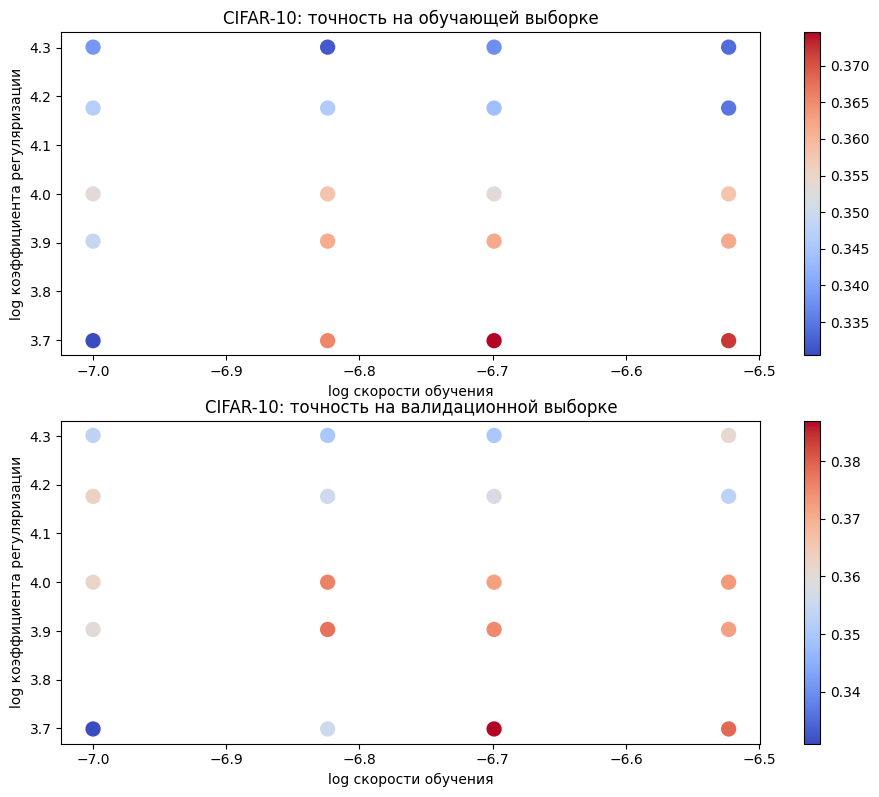

In [35]:
# Визуализируем результаты подбора гиперпараметров
import math
x_scatter = [math.log10(x[0]) for x in results]
y_scatter = [math.log10(x[1]) for x in results]

# график точности на обучающей выборке
marker_size = 100
colors = [results[x][0] for x in results]
plt.subplot(2, 1, 1)
plt.tight_layout(pad=3)
plt.scatter(x_scatter, y_scatter, marker_size, c=colors, cmap=plt.cm.coolwarm)
plt.colorbar()
plt.xlabel('log скорости обучения')
plt.ylabel('log коэффициента регуляризации')
plt.title('CIFAR-10: точность на обучающей выборке')

# график точности на валидационной выборке
colors = [results[x][1] for x in results] # размер маркеров по умолчанию — 20
plt.subplot(2, 1, 2)
plt.scatter(x_scatter, y_scatter, marker_size, c=colors, cmap=plt.cm.coolwarm)
plt.colorbar()
plt.xlabel('log скорости обучения')
plt.ylabel('log коэффициента регуляризации')
plt.title('CIFAR-10: точность на валидационной выборке')
plt.show()

In [36]:
# Оцениваем лучший классификатор Softmax на тестовой выборке
y_test_pred = best_softmax.predict(X_test)
test_accuracy = np.mean(y_test == y_test_pred)
print('Классификатор Softmax на исходных пикселях, итоговая точность на тестовой выборке: %f' % test_accuracy)

Классификатор Softmax на исходных пикселях, итоговая точность на тестовой выборке: 0.374000


In [37]:
# Сохраняем лучшую модель Softmax (файл появится в папке `dlcv/saved/`).
best_softmax.save("best_softmax.npy")

best_softmax.npy сохранён.


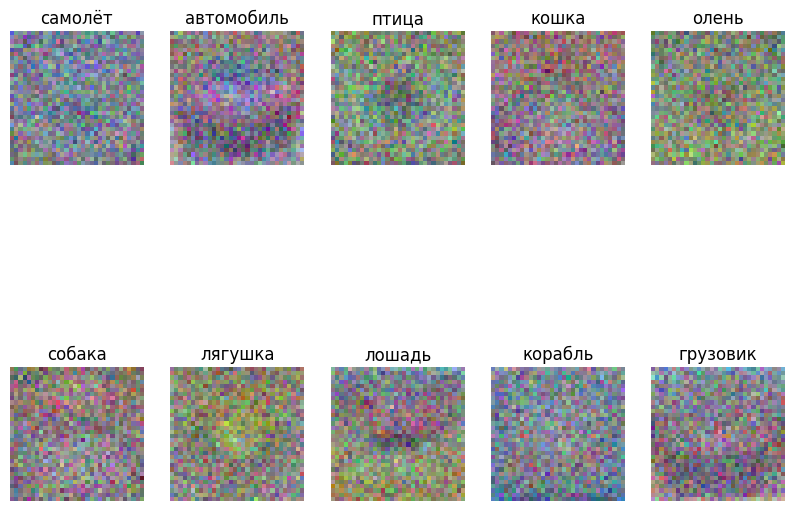

In [38]:
# Визуализируем обученные веса для каждого класса.
# В зависимости от выбранных скорости обучения и коэффициента регуляризации
# картинки могут получиться как наглядными, так и не очень.
w = best_softmax.W[:-1,:] # отбрасываем смещение
w = w.reshape(32, 32, 3, 10)
w_min, w_max = np.min(w), np.max(w)
classes = ['самолёт', 'автомобиль', 'птица', 'кошка', 'олень', 'собака', 'лягушка', 'лошадь', 'корабль', 'грузовик']
for i in range(10):
    plt.subplot(2, 5, i + 1)

    # Масштабируем веса в диапазон от 0 до 255
    wimg = 255.0 * (w[:, :, :, i].squeeze() - w_min) / (w_max - w_min)
    plt.imshow(wimg.astype('uint8'))
    plt.axis('off')
    plt.title(classes[i])

**Вопрос 3**

Опишите, как выглядят визуализированные веса вашего классификатора Softmax, и кратко объясните, почему они выглядят именно так.

**Ваш ответ:** 

Веса выглядят как размытые и шумные наборы пикселей. У некоторых видны характерные цвета и грубые силуэты. У корабля преобладают синие оттенки, у лягушки - зелёные, а у автомобилей и грузовиков заметна тёмная область в нижней части. Чётких объектов нет, поскольку линейный классификатор изучает только один общий шаблон для каждого класса и фактически усредняет изображения с разным фоном, положением и внешним видом объектов. Клетчатый шум связан с тем, что отдельные пиксельные веса обучены неточно и чувствительны к вариациям обучающих изображений.


**Вопрос 4** — *Верно или неверно*

Пусть общее значение функции потерь на обучающей выборке определяется как сумма потерь по всем обучающим примерам. Можно добавить в обучающую выборку новый объект так, что потери softmax изменятся, а потери SVM останутся прежними. (Определение функции потерь SVM см. в вопросе 2.)

**Ваш ответ:** верно

**Ваше объяснение:** 

Если новый объект классифицируется правильно с достаточным запасом, его SVM-потеря равна нулю, поэтому общая потеря SVM не изменится. Потеря Softmax для объекта обычно положительна, поскольку вероятность правильного класса меньше единицы. Поэтому добавление этого объекта изменит общую Softmax-потерю.